# Bài Thực Hành 3: Dự Đoán Chuỗi Thời Gian Sử Dụng Machine Learning Models

**Mục tiêu:**
- Chuyển bài toán chuỗi thời gian sang học có giám sát (Supervised Learning).
- Huấn luyện mô hình XGBoost Regressor.
- Đánh giá chất lượng dự báo.

## Bước 1. Chuẩn bị dữ liệu

- Đọc dữ liệu `AEP_hourly.csv` (tiêu thụ điện hàng giờ từ PJM, đơn vị Megawatt).
- Định dạng cột `Datetime`, sắp xếp theo trình tự thời gian.
- Xử lý các mốc trùng lặp (Daylight Saving Time) và nội suy các mốc thời gian thiếu.
- Thống kê mô tả (`describe`) chuỗi dữ liệu.
- Vẽ biểu đồ trực quan hóa chuỗi thời gian cùng các đường ngưỡng thống kê (`mean`, `min`, `max`), chú thích đặc trưng và lưu ảnh vào thư mục `docs/images/`.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Tạo thư mục lưu ảnh nếu chưa có
os.makedirs('../docs/images', exist_ok=True)

In [6]:
# 1. Đọc dữ liệu thô
data_path = '../data/raw/AEP_hourly.csv' if os.path.exists('../data/raw/AEP_hourly.csv') else '../data/AEP_hourly.csv'
df_raw = pd.read_csv(data_path)

# 2. Chuyển đổi Datetime và sắp xếp tăng dần
df_raw['Datetime'] = pd.to_datetime(df_raw['Datetime'])
df_sorted = df_raw.sort_values('Datetime').reset_index(drop=True)

# 3. Xử lý trùng lặp giờ (DST) và tạo lưới thời gian đều 1 giờ (freq='h')
series = df_sorted.groupby('Datetime')['AEP_MW'].mean().asfreq('h')
series = series.interpolate(method='time')

print('Dữ liệu sau khi làm sạch và tạo chuỗi liên tục:')
print(series.head())
print(f'\nTổng số giờ liên tục: {len(series):,} quan sát (từ {series.index.min()} đến {series.index.max()})')
print(f'Số giá trị khuyết (NaN): {series.isnull().sum()}')

Dữ liệu sau khi làm sạch và tạo chuỗi liên tục:
Datetime
2004-10-01 01:00:00    12379.0
2004-10-01 02:00:00    11935.0
2004-10-01 03:00:00    11692.0
2004-10-01 04:00:00    11597.0
2004-10-01 05:00:00    11681.0
Freq: h, Name: AEP_MW, dtype: float64

Tổng số giờ liên tục: 121,296 quan sát (từ 2004-10-01 01:00:00 đến 2018-08-03 00:00:00)
Số giá trị khuyết (NaN): 0


In [7]:
# 4. Thống kê mô tả dữ liệu (describe)
stats = series.describe()
print('Thống kê mô tả (describe) của chuỗi phụ tải AEP_MW:')
print(stats)

min_date = series.idxmin()
max_date = series.idxmax()
print('\nCác chỉ số thống kê chính:')
print(f'- Số quan sát (count):   {stats["count"]:,.0f} giờ')
print(f'- Trung bình (mean):     {stats["mean"]:,.2f} MW')
print(f'- Độ lệch chuẩn (std):  {stats["std"]:,.2f} MW')
print(f'- Thấp nhất (min):       {stats["min"]:,.2f} MW (vào lúc {min_date})')
print(f'- Tứ phân vị 25% (Q1):   {stats["25%"]:,.2f} MW')
print(f'- Trung vị (50% / Q2):   {stats["50%"]:,.2f} MW')
print(f'- Tứ phân vị 75% (Q3):   {stats["75%"]:,.2f} MW')
print(f'- Cao nhất (max):        {stats["max"]:,.2f} MW (vào lúc {max_date})')

Thống kê mô tả (describe) của chuỗi phụ tải AEP_MW:
count    121296.000000
mean      15499.150331
std        2591.379068
min        9581.000000
25%       13629.000000
50%       15309.000000
75%       17200.000000
max       25695.000000
Name: AEP_MW, dtype: float64

Các chỉ số thống kê chính:
- Số quan sát (count):   121,296 giờ
- Trung bình (mean):     15,499.15 MW
- Độ lệch chuẩn (std):  2,591.38 MW
- Thấp nhất (min):       9,581.00 MW (vào lúc 2016-10-02 05:00:00)
- Tứ phân vị 25% (Q1):   13,629.00 MW
- Trung vị (50% / Q2):   15,309.00 MW
- Tứ phân vị 75% (Q3):   17,200.00 MW
- Cao nhất (max):        25,695.00 MW (vào lúc 2008-10-20 14:00:00)


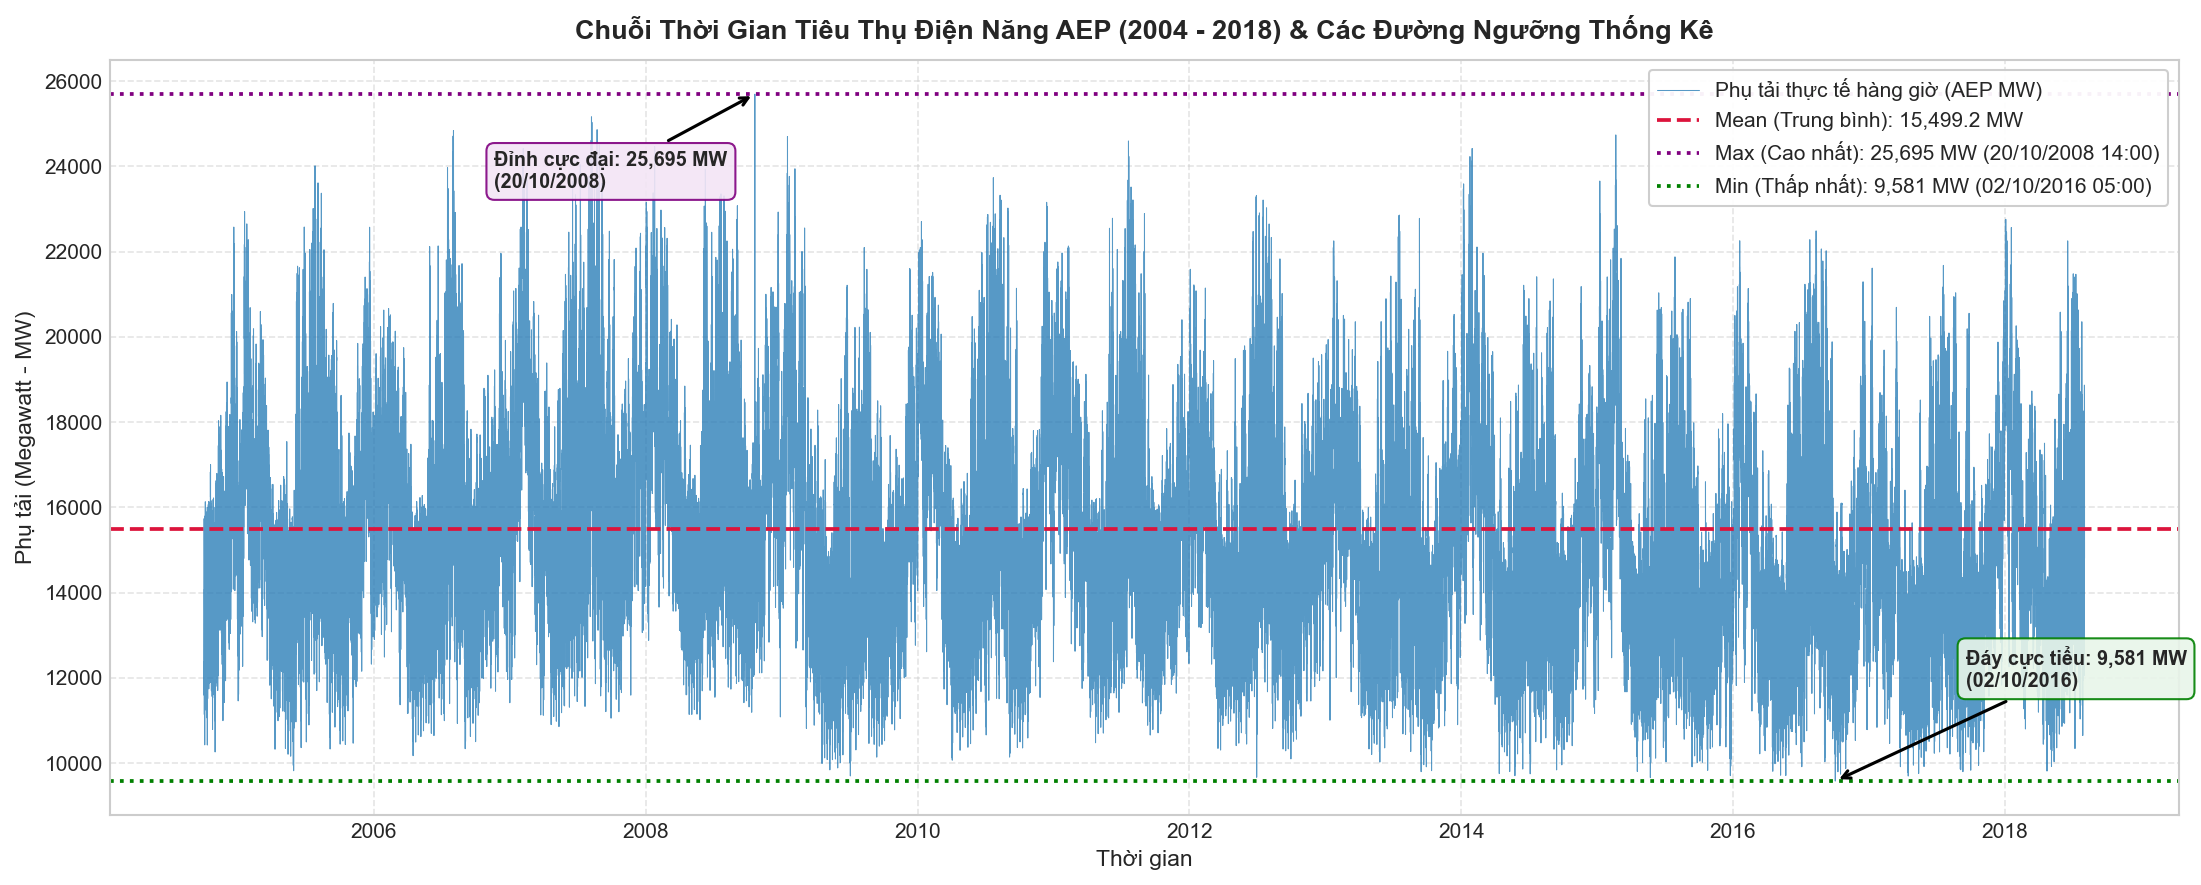

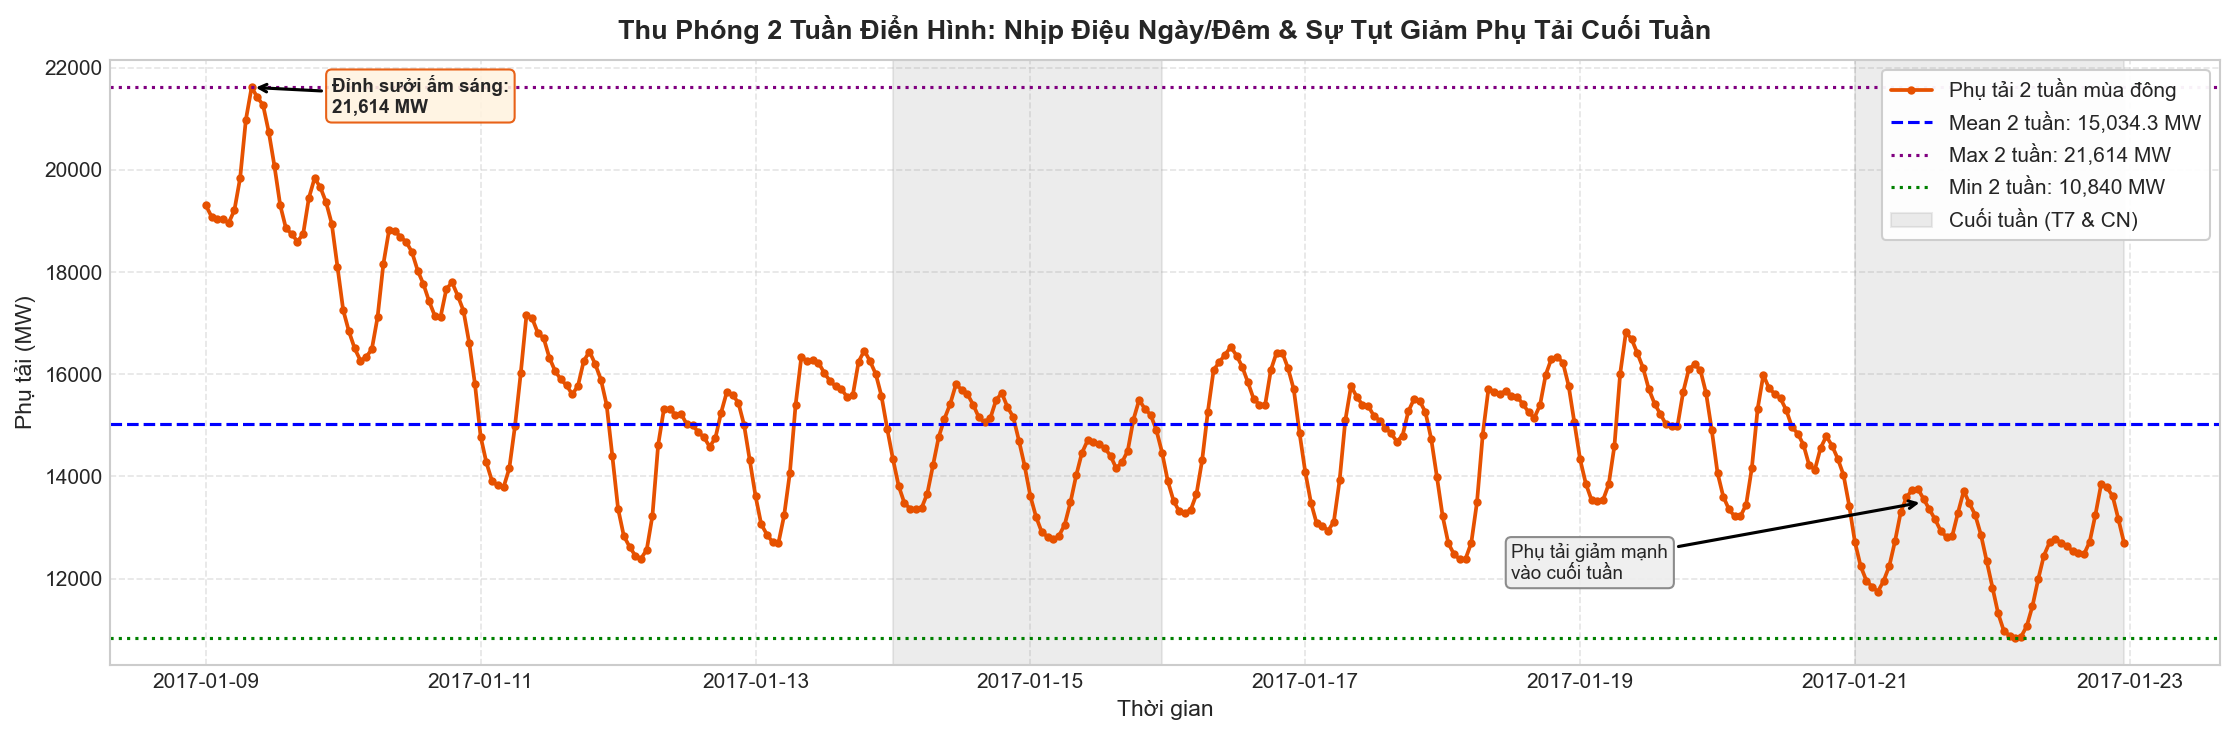

In [8]:
# 5. Vẽ biểu đồ chuỗi thời gian cùng các đường min, max, mean, chú thích và lưu vào docs/images/

mean_val = series.mean()
min_val = series.min()
max_val = series.max()

# --- BIỂU ĐỒ 1: Toàn cảnh 2004 - 2018 với đường Mean, Min, Max và Chú thích ---
plt.figure(figsize=(15, 6), dpi=150)
plt.plot(series.index, series.values, color='#1f77b4', linewidth=0.5, alpha=0.75, label='Phụ tải thực tế hàng giờ (AEP MW)')

# Vẽ các đường ngưỡng min, max, mean
plt.axhline(mean_val, color='crimson', linestyle='--', linewidth=1.8, label=f'Mean (Trung bình): {mean_val:,.1f} MW')
plt.axhline(max_val, color='purple', linestyle=':', linewidth=1.8, label=f'Max (Cao nhất): {max_val:,.0f} MW ({max_date.strftime("%d/%m/%Y %H:00")})')
plt.axhline(min_val, color='green', linestyle=':', linewidth=1.8, label=f'Min (Thấp nhất): {min_val:,.0f} MW ({min_date.strftime("%d/%m/%Y %H:00")})')

# Chú thích điểm cực đại và cực tiểu
plt.annotate(f'Đỉnh cực đại: {max_val:,.0f} MW\n({max_date.strftime("%d/%m/%Y")})', 
             xy=(max_date, max_val), 
             xytext=(max_date - pd.Timedelta(days=700), max_val - 2200),
             arrowprops=dict(facecolor='purple', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#F3E5F5', edgecolor='purple', alpha=0.9),
             fontsize=9.5, fontweight='bold')

plt.annotate(f'Đáy cực tiểu: {min_val:,.0f} MW\n({min_date.strftime("%d/%m/%Y")})', 
             xy=(min_date, min_val), 
             xytext=(min_date + pd.Timedelta(days=350), min_val + 2200),
             arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#E8F5E9', edgecolor='green', alpha=0.9),
             fontsize=9.5, fontweight='bold')

plt.title('Chuỗi Thời Gian Tiêu Thụ Điện Năng AEP (2004 - 2018) & Các Đường Ngưỡng Thống Kê', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Phụ tải (Megawatt - MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, framealpha=0.95, facecolor='white')
plt.tight_layout()
plt.savefig('../docs/images/01_aep_full_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

# --- BIỂU ĐỒ 2: Thu phóng 2 tuần điển hình với đường Mean 2 tuần và Chú thích chu kỳ ---
sample_2weeks = series.loc['2017-01-09':'2017-01-22']
sample_mean = sample_2weeks.mean()
sample_max = sample_2weeks.max()
sample_min = sample_2weeks.min()
sample_max_date = sample_2weeks.idxmax()

plt.figure(figsize=(15, 5), dpi=150)
plt.plot(sample_2weeks.index, sample_2weeks.values, color='#e65100', linewidth=1.8, marker='o', markersize=3, label='Phụ tải 2 tuần mùa đông')
plt.axhline(sample_mean, color='blue', linestyle='--', linewidth=1.5, label=f'Mean 2 tuần: {sample_mean:,.1f} MW')
plt.axhline(sample_max, color='purple', linestyle=':', linewidth=1.5, label=f'Max 2 tuần: {sample_max:,.0f} MW')
plt.axhline(sample_min, color='green', linestyle=':', linewidth=1.5, label=f'Min 2 tuần: {sample_min:,.0f} MW')

# Vùng tô xám đánh dấu hai kỳ nghỉ cuối tuần (Thứ Bảy & Chủ Nhật)
plt.axvspan(pd.Timestamp('2017-01-14 00:00:00'), pd.Timestamp('2017-01-15 23:00:00'), color='gray', alpha=0.15, label='Cuối tuần (T7 & CN)')
plt.axvspan(pd.Timestamp('2017-01-21 00:00:00'), pd.Timestamp('2017-01-22 23:00:00'), color='gray', alpha=0.15)

# Chú thích đỉnh phụ tải và sự sụt giảm cuối tuần
plt.annotate(f'Đỉnh sưởi ấm sáng:\n{sample_max:,.0f} MW',
             xy=(sample_max_date, sample_max),
             xytext=(sample_max_date + pd.Timedelta(hours=14), sample_max - 500),
             arrowprops=dict(facecolor='#e65100', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3E0', edgecolor='#e65100', alpha=0.9),
             fontsize=9, fontweight='bold')

plt.annotate('Phụ tải giảm mạnh\nvào cuối tuần',
             xy=(pd.Timestamp('2017-01-21 12:00:00'), 13500),
             xytext=(pd.Timestamp('2017-01-18 12:00:00'), 12000),
             arrowprops=dict(facecolor='dimgray', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#EEEEEE', edgecolor='gray', alpha=0.9),
             fontsize=9)

plt.title('Thu Phóng 2 Tuần Điển Hình: Nhịp Điệu Ngày/Đêm & Sự Tụt Giảm Phụ Tải Cuối Tuần', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Phụ tải (MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, framealpha=0.95, facecolor='white')
plt.tight_layout()
plt.savefig('../docs/images/02_aep_zoomin_2weeks.png', dpi=150, bbox_inches='tight')
plt.show()

**Nhận xét từ thống kê mô tả & biểu đồ:**
1. **Mức trung bình & biến động:** Mức tiêu thụ điện trung bình đạt **~15.500 MW**, dao động trong khoảng $9.581 - 25.695\text{ MW}$ với độ lệch chuẩn $2.591\text{ MW}$.
2. **Đỉnh cực đại (Max):** Đạt kỷ lục $25.695\text{ MW}$ vào ngày **20/10/2008** (và các đợt rét cực đoan mùa đông), đây là những biến cố thời tiết thực tế.
3. **Chu kỳ ngày/đêm & tuần:** Đồ thị thu phóng 2 tuần cho thấy rõ 2 đỉnh phụ tải mỗi ngày (đỉnh sáng và đỉnh tối) cùng vùng phụ tải tụt sâu vào Thứ Bảy, Chủ Nhật. Đây là thông tin cơ sở để quyết định số lượng biến trễ ở **Bước 2** (ví dụ lag 24h và lag 168h).

## Bước 2. Tạo Lag Features (Supervised Learning)

**1. Mục tiêu:** Chuyển đổi bài toán chuỗi thời gian đơn biến $y_t$ thành bài toán học có giám sát (Supervised Learning).

**2. Mô hình hóa toán học:**
Tại mỗi thời điểm $t$, ta dự đoán giá trị phụ tải $y_t$ dựa trên tập hợp các giá trị quan sát trong quá khứ:
$$\hat{y}_t = f(\mathbf{x}_t) = f(y_{t-1}, y_{t-2}, \dots, y_{t-p})$$
Trong đó:
- $y_t$ (**Target**): Giá trị phụ tải điện thực tế cần dự đoán tại thời điểm $t$ ($MW$).
- $\mathbf{x}_t$ (**Ma trận đặc trưng / Lag Predictors**): Tập hợp các biến trễ thời gian đóng vai trò là biến giải thích.

**3. Thiết kế bộ đặc trưng đa chu kỳ (Multi-Period Lag Architecture):**
Dữ liệu phụ tải điện thực tế mang đặc tính chu kỳ kép: chu kỳ ngày (24 giờ) và chu kỳ tuần (168 giờ). Ta thiết kế bộ đặc trưng đa chu kỳ gồm **29 đặc trưng trễ**:
- **Nhóm 1 - Quán tính ngắn hạn & Chu kỳ ngày ($lag_1 \rightarrow lag_{24}$):** 24 giờ liên tục gần nhất, giúp mô hình bắt trọn vẹn xu hướng tăng/giảm liền kề và chu kỳ 24h của ngày hôm trước.
- **Nhóm 2 - Các mốc ngày trước ($lag_{48}, lag_{72}$):** Cùng giờ của 2 ngày và 3 ngày trước, cung cấp thêm thông tin về nhịp điệu giữa tuần.
- **Nhóm 3 - Cụm chu kỳ tuần 7 ngày ($lag_{167}, lag_{168}, lag_{169}$):** Cùng giờ của tuần trước ($168\text{ giờ} = 7 \times 24\text{h}$) cùng cửa sổ $\pm 1$ giờ lân cận. Đây là đặc trưng then chốt giúp mô hình phân biệt chính xác mức tiêu thụ điện giữa ngày làm việc (Thứ Hai – Thứ Sáu) và ngày nghỉ cuối tuần (Thứ Bảy, Chủ Nhật).

**4. Cơ chế trượt thời gian & xử lý giá trị khuyết (NaN):**
- Sử dụng hàm `shift(i)` của Pandas để dịch chuyển chuỗi dữ liệu lùi lại $i$ bước thời gian.
- Bậc trễ xa nhất là $169$ bước thời gian, sinh ra $169$ dòng `NaN` ở đầu chuỗi (do không đủ lịch sử trượt).
- Thực hiện `.dropna()` để loại bỏ $169$ dòng này. Với tổng cộng $121.296$ giờ, việc loại bỏ $169$ dòng chỉ làm giảm $\approx 0,139\%$ dữ liệu, bảo toàn trọn vẹn hơn $99,86\%$ chuỗi thời gian.

### 2.1. Khảo Sát Tự Tương Quan (ACF & PACF) — Cơ Sở Khoa Học Chọn $p = 24$

Trước khi biến đổi dữ liệu thành các biến trễ, ta cần trả lời câu hỏi cốt lõi: **"Tại sao lại chọn $p = 24$ bậc trễ? Căn cứ vào đâu?"**

Trong phân tích chuỗi thời gian:
* **Hàm tự tương quan (ACF - Autocorrelation Function):** Đo lường mức độ tương quan tổng thể giữa $y_t$ và các giá trị quá khứ $y_{t-k}$ (bao gồm cả tương quan trực tiếp và gián tiếp).
* **Hàm tự tương quan từng phần (PACF - Partial Autocorrelation Function):** Đo lường tương quan **trực tiếp thuần túy** giữa $y_t$ và $y_{t-k}$ sau khi đã triệt tiêu toàn bộ ảnh hưởng của các bước thời gian trung gian ($y_{t-1}, y_{t-2}, \dots, y_{t-k+1}$).

Đã lưu biểu đồ ACF & PACF vào: ../docs/images/04_acf_pacf_analysis.png

=== GIÁ TRỊ ĐỊNH LƯỢNG ACF & PACF TẠI CÁC TRỄ THEN CHỐT ===
- Lag  1: ACF =  0.9762  |  PACF =  0.9762
- Lag  2: ACF =  0.9147  |  PACF = -0.8149
- Lag  3: ACF =  0.8293  |  PACF =  0.2608
- Lag 12: ACF =  0.2915  |  PACF =  0.1055
- Lag 23: ACF =  0.8579  |  PACF = -0.1619
- Lag 24: ACF =  0.8741  |  PACF = -0.4873
- Lag 25: ACF =  0.8472  |  PACF = -0.4817
- Lag 48: ACF =  0.7391  |  PACF = -0.0074
- Lag 72: ACF =  0.6859  |  PACF = -0.1031


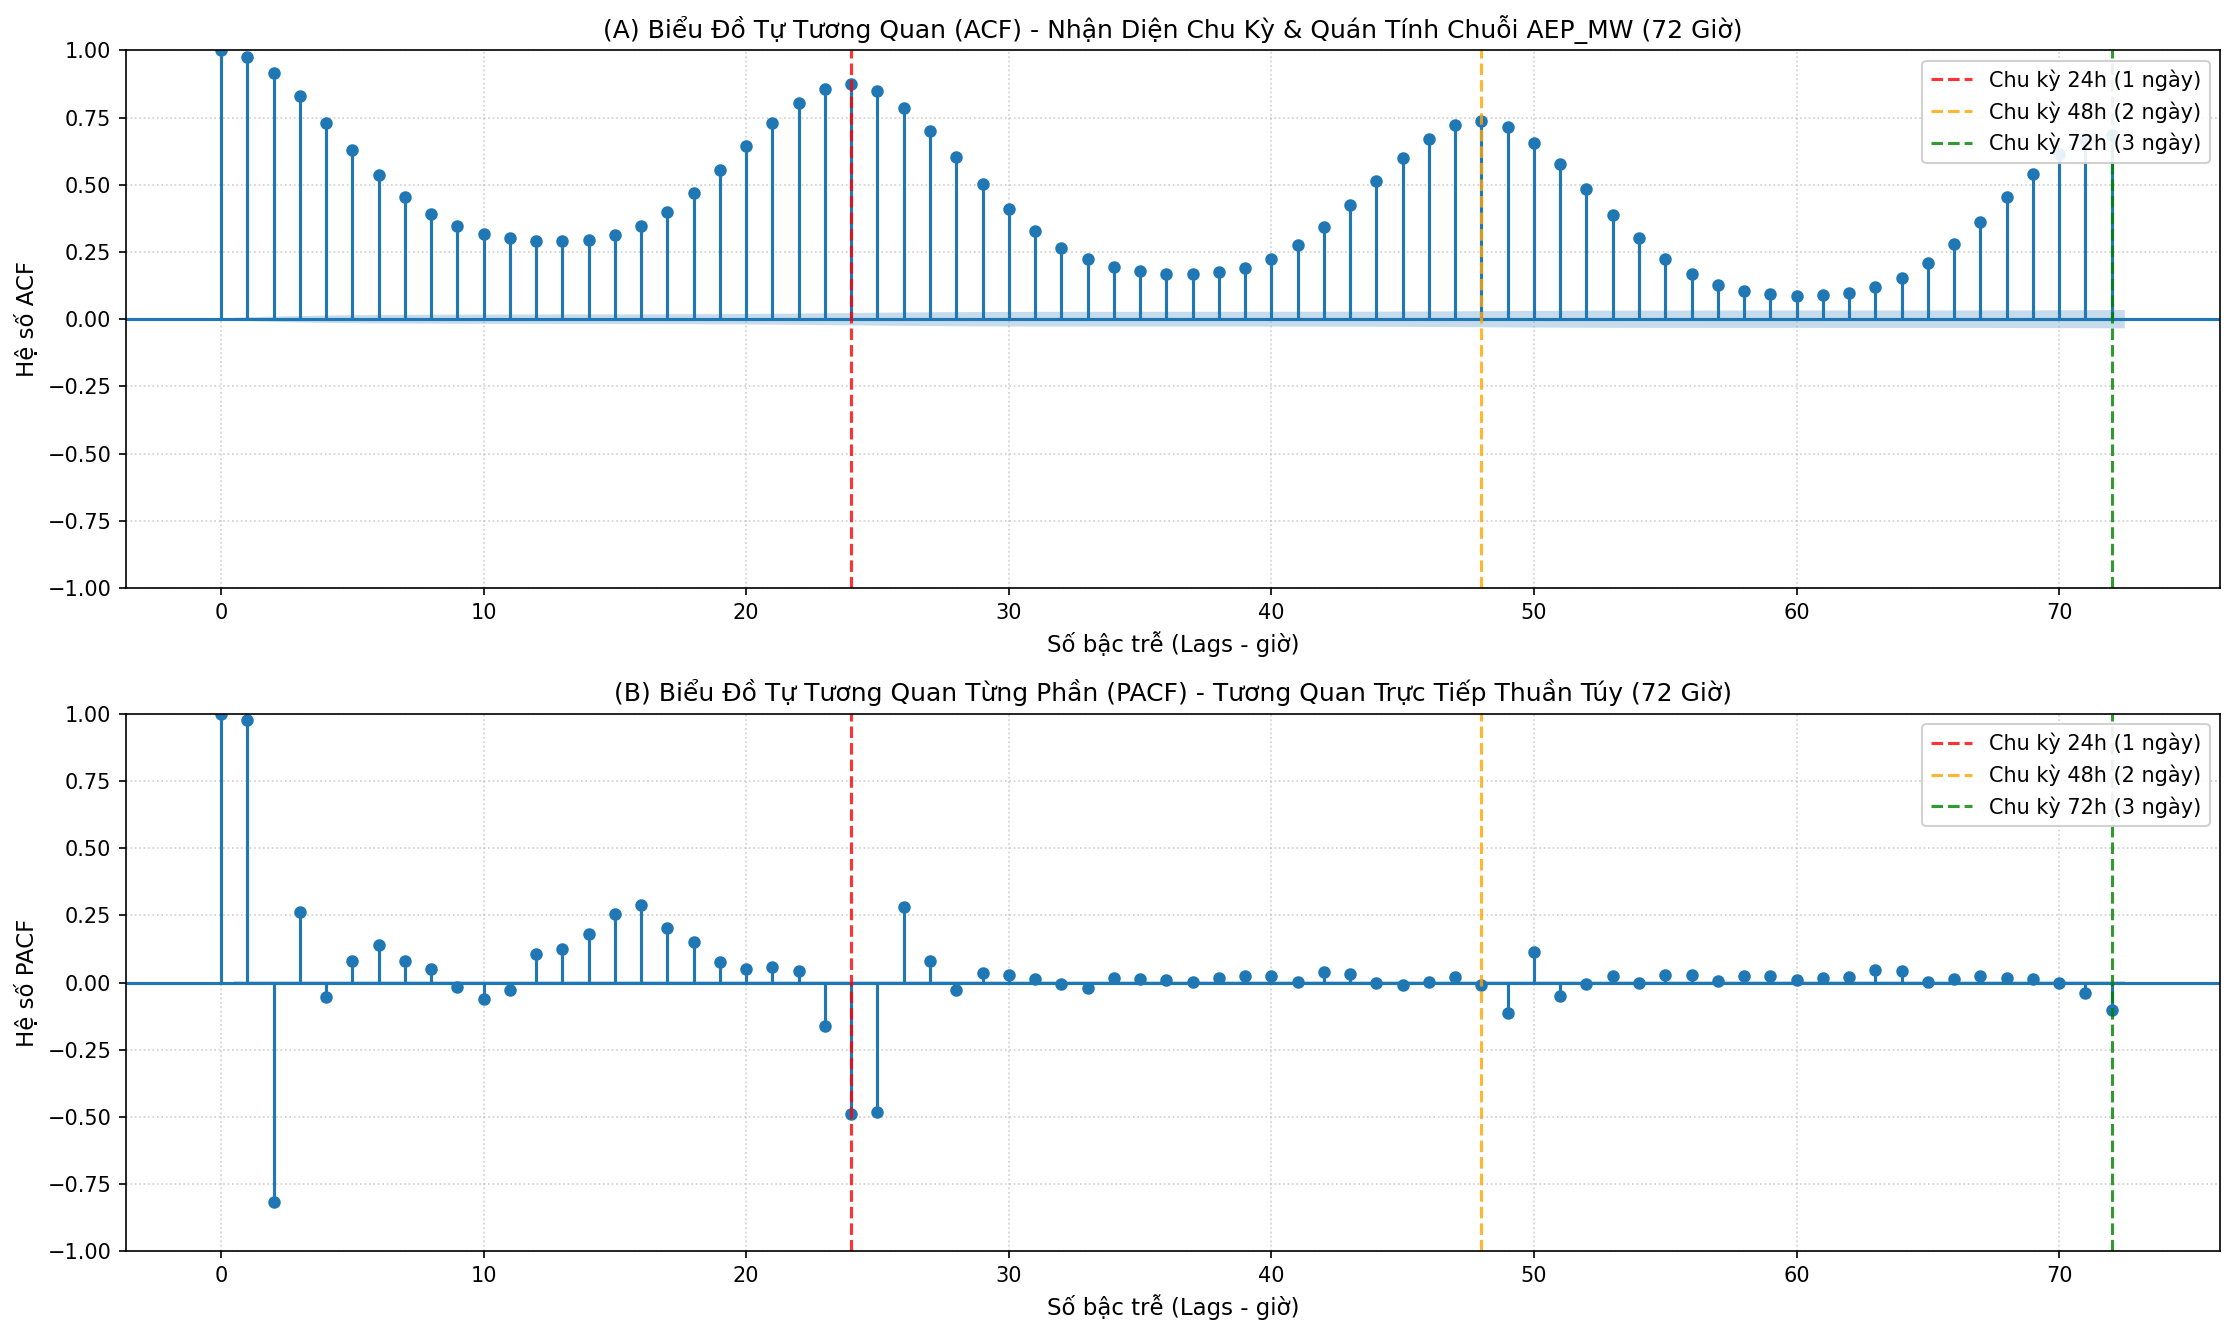

In [8]:
# ==============================================================================
# KHẢO SÁT ACF & PACF: CƠ SỞ ĐỊNH DANH BẬC TRỄ (LAG ORDER p = 24)
# ==============================================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), dpi=150)

# 1. Vẽ ACF (Hàm tự tương quan - Autocorrelation Function)
plot_acf(series, lags=72, ax=ax1, alpha=0.05, 
         title='(A) Biểu Đồ Tự Tương Quan (ACF) - Nhận Diện Chu Kỳ & Quán Tính Chuỗi AEP_MW (72 Giờ)')
ax1.axvline(x=24, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 24h (1 ngày)')
ax1.axvline(x=48, color='orange', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 48h (2 ngày)')
ax1.axvline(x=72, color='green', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 72h (3 ngày)')
ax1.set_xlabel('Số bậc trễ (Lags - giờ)', fontsize=11)
ax1.set_ylabel('Hệ số ACF', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

# 2. Vẽ PACF (Hàm tự tương quan từng phần - Partial Autocorrelation Function)
plot_pacf(series, lags=72, ax=ax2, alpha=0.05, method='ywm',
          title='(B) Biểu Đồ Tự Tương Quan Từng Phần (PACF) - Tương Quan Trực Tiếp Thuần Túy (72 Giờ)')
ax2.axvline(x=24, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 24h (1 ngày)')
ax2.axvline(x=48, color='orange', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 48h (2 ngày)')
ax2.axvline(x=72, color='green', linestyle='--', linewidth=1.5, alpha=0.8, label='Chu kỳ 72h (3 ngày)')
ax2.set_xlabel('Số bậc trễ (Lags - giờ)', fontsize=11)
ax2.set_ylabel('Hệ số PACF', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()

# Lưu biểu đồ vào docs/images/
image_path = '../docs/images/04_acf_pacf_analysis.png'
os.makedirs(os.path.dirname(image_path), exist_ok=True)
fig.savefig(image_path, bbox_inches='tight')
print(f"Đã lưu biểu đồ ACF & PACF vào: {image_path}")
plt.show()

# In thống kê định lượng các mốc trễ then chốt
acf_vals = acf(series, nlags=72)
pacf_vals = pacf(series, nlags=72, method='ywm')

print("\n=== GIÁ TRỊ ĐỊNH LƯỢNG ACF & PACF TẠI CÁC TRỄ THEN CHỐT ===")
for lag in [1, 2, 3, 12, 23, 24, 25, 48, 72]:
    print(f"- Lag {lag:2d}: ACF = {acf_vals[lag]:7.4f}  |  PACF = {pacf_vals[lag]:7.4f}")


**Nhận xét từ biểu đồ ACF & PACF:**
1. **Biểu đồ ACF (Hình sin suy giảm chậm - Sinusoidal Decay):**
   - **Quán tính ngắn hạn cực mạnh:** Hệ số ACF tại `lag 1` đạt **$0.9762$**, khẳng định giá trị phụ tải giờ hiện tại phụ thuộc chặt chẽ vào giờ ngay trước đó.
   - **Đáy tương quan lệch pha ngày/đêm:** Giảm dần xuống đáy cục bộ tại `lag 12` ($0.2915$) do sự đối lập giữa giờ cao điểm sinh hoạt ban ngày và giờ thấp điểm ban đêm.
   - **Đỉnh chu kỳ 24 giờ:** Tăng vọt trở lại và tạo đỉnh cục bộ rất mạnh tại **`lag 24` ($0.8741$)**, tiếp tục lặp lại tại `lag 48` ($0.7391$) và `lag 72` ($0.6859$).
2. **Biểu đồ PACF (Tương quan trực tiếp):**
   - PACF có các vạch tương quan trực tiếp vượt trội tại **`lag 1` ($0.9762$)** và **`lag 24, 25` ($-0.4873, -0.4817$)**, sau đó suy giảm rõ rệt ở các lag xa hơn.
3. **Kết luận khoa học:** Việc chọn **$p = 24$** bậc trễ là hoàn toàn chuẩn xác vì bao trọn vẹn đúng 1 chu kỳ ngày tự nhiên ($24	ext{ giờ}$), đồng thời cung cấp đầy đủ cả đặc trưng quán tính ngắn hạn (`lag_1`) lẫn đặc trưng chu kỳ (`lag_24`).

In [9]:
# ==============================================================================
# BƯỚC 2: TẠO LAG FEATURES (SUPERVISED LEARNING)
# Thiết kế bộ đặc trưng đa chu kỳ: 24h gần nhất + 2-3 ngày trước + Chu kỳ tuần 7 ngày
# ==============================================================================

def create_lag_features(data_series):
    """
    Chuyển đổi chuỗi thời gian đơn biến thành bài toán học có giám sát với:
    - 24 giờ gần nhất: lag_1 -> lag_24 (Quán tính ngắn hạn & Chu kỳ ngày)
    - 2 ngày & 3 ngày trước: lag_48, lag_72 (Mốc tham chiếu giữa tuần)
    - Cụm chu kỳ tuần 7 ngày: lag_167, lag_168, lag_169 (Chu kỳ tuần 168h +- 1h)
    
    Parameters:
    -----------
    data_series : pd.Series
        Chuỗi thời gian liên tục với DatetimeIndex.
        
    Returns:
    --------
    df_features : pd.DataFrame
        DataFrame chứa cột target 'y' và 29 cột đặc trưng lag,
        đã loại bỏ các dòng NaN do trượt dữ liệu (169 dòng đầu).
    """
    df_feat = pd.DataFrame({'y': data_series})
    
    # 1. Nhóm quán tính ngắn hạn & chu kỳ 24 giờ
    for i in range(1, 25):
        df_feat[f'lag_{i}'] = data_series.shift(i)
        
    # 2. Nhóm mốc 2 ngày và 3 ngày trước
    df_feat['lag_48'] = data_series.shift(48)
    df_feat['lag_72'] = data_series.shift(72)
    
    # 3. Nhóm cụm chu kỳ tuần 7 ngày (168 giờ +- 1 giờ)
    df_feat['lag_167'] = data_series.shift(167)
    df_feat['lag_168'] = data_series.shift(168)
    df_feat['lag_169'] = data_series.shift(169)
        
    # Loại bỏ các dòng đầu chứa NaN (tối đa 169 dòng do lag_169)
    df_clean = df_feat.dropna()
    return df_clean

# 1. Khởi tạo ma trận đặc trưng giám sát
df_supervised = create_lag_features(series)

# 2. Kiểm tra thông tin tập dữ liệu sau khi biến đổi
print("=== KẾT QUẢ TẠO LAG FEATURES ĐA CHU KỲ (24h + 48h + 72h + 168h) ===")
print(f"- Kích thước ma trận (dòng, cột): {df_supervised.shape}")
print(f"- Số dòng ban đầu:               {len(series):,} dòng")
print(f"- Số dòng sau khi dropna:        {len(df_supervised):,} dòng (mất {len(series) - len(df_supervised)} dòng đầu do shift)")
print(f"- Số giá trị thiếu (NaN):        {df_supervised.isnull().sum().sum()}")
print(f"- Dải thời gian khả dụng:        {df_supervised.index.min()}  -->  {df_supervised.index.max()}")
print(f"- Số lượng cột đặc trưng lag:    {len(df_supervised.columns) - 1} cột (gồm lag_1->24, lag_48, lag_72, lag_167->169)")

print("\n--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---")
sample_cols = ['y', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_72', 'lag_168', 'lag_169']
print(df_supervised[sample_cols].head())

print("\n--- 5 DÒNG CUỐI CÙNG CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---")
print(df_supervised[sample_cols].tail())


=== KẾT QUẢ TẠO LAG FEATURES ĐA CHU KỲ (24h + 48h + 72h + 168h) ===
- Kích thước ma trận (dòng, cột): (121127, 30)
- Số dòng ban đầu:               121,296 dòng
- Số dòng sau khi dropna:        121,127 dòng (mất 169 dòng đầu do shift)
- Số giá trị thiếu (NaN):        0
- Dải thời gian khả dụng:        2004-10-08 02:00:00  -->  2018-08-03 00:00:00
- Số lượng cột đặc trưng lag:    29 cột (gồm lag_1->24, lag_48, lag_72, lag_167->169)

--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---
                           y    lag_1    lag_2   lag_24   lag_48   lag_72  lag_168  lag_169
Datetime                                                                                   
2004-10-08 02:00:00  12046.0  12468.0  13271.0  12054.0  12347.0  12126.0  11935.0  12379.0
2004-10-08 03:00:00  11749.0  12046.0  12468.0  11745.0  12192.0  11926.0  11692.0  11935.0
2004-10-08 04:00:00  11784.0  11749.0  12046.0  11757.0  12164.0  11914.0  11597.0  11692.0
2004-10-08 05:00:00  11919.0  11784.0  11749.0  1204

**Đánh giá & Kết luận Bước 2:**
1. **Chuyển đổi thành công:** Đã cấu trúc hóa chuỗi đơn biến $121.296$ giờ thành bảng dữ liệu học có giám sát gồm **$121.127$ mẫu** và **$30$ cột** ($1$ cột target $y$ và $29$ đặc trưng trễ gồm `lag_1` $\rightarrow$ `lag_24`, `lag_48`, `lag_72`, `lag_167`, `lag_168`, `lag_169`).
2. **Nắm bắt đa chu kỳ (Multi-Period Seasonality):** 
   - Quán tính ngày và đêm được bảo toàn trọn vẹn qua 24 lag liên tục.
   - Nhịp điệu tuần được củng cố bằng cụm `lag_167, lag_168, lag_169`, loại bỏ điểm mù dự báo khi chuyển tiếp từ cuối tuần sang đầu tuần.
3. **Bảo toàn nguyên tắc nhân quả (No Data Leakage):** Mọi đặc trưng tại thời điểm $t$ đều được lấy nghiêm ngặt từ quá khứ ($t-1 \rightarrow t-169$). Không có bất kỳ thông tin tương lai nào bị rò rỉ vào ma trận đặc trưng.
4. **Tổn thất mẫu tối thiểu:** Chỉ mất $169$ dòng đầu tiên (~$0,139\%$ dữ liệu) do quá trình `shift()`, dải thời gian liên tục từ `2004-10-08 02:00:00` đến `2018-08-03 00:00:00` (~13,8 năm) được bảo toàn nguyên vẹn.
5. **Sẵn sàng cho Bước 3:** Dữ liệu đã đạt chuẩn để tách $X - y$ và phân chia tập huấn luyện / kiểm thử theo thời gian.

## Bước 3. Chia X – y (Tách Ma Trận Đặc Trưng và Biến Mục Tiêu)

Trong bài toán học có giám sát cho chuỗi thời gian, ta cần phân tách cấu trúc dữ liệu thành 2 thành phần độc lập:
1. **Ma trận đặc trưng ($X \in \mathbb{R}^{N \times 29}$):** Chứa 29 biến đầu vào trong quá khứ (`lag_1` đến `lag_24`, `lag_48`, `lag_72`, `lag_167`, `lag_168`, `lag_169`). Mỗi hàng $\mathbf{x}_t$ biểu diễn trạng thái lịch sử của chuỗi phụ tải trong các mốc giờ, ngày và tuần trước đó.
2. **Vector biến mục tiêu ($y \in \mathbb{R}^N$):** Chứa nhãn giá trị thực tế tại thời điểm hiện tại $y_t$ mà mô hình cần học cách dự báo:
$$\hat{y}_t = f(\mathbf{x}_t) = f(y_{t-1}, \dots, y_{t-24}, y_{t-48}, y_{t-72}, y_{t-167}, y_{t-168}, y_{t-169})$$

**Các nguyên tắc quan trọng cần đảm bảo:**
- **Không làm mất DatetimeIndex:** Cả $X$ và $y$ phải giữ nguyên trục thời gian `DatetimeIndex` đồng nhất để phục vụ bước phân chia Train/Val/Test theo thứ tự thời gian (Bước 4) và trực quan hóa kết quả dự báo.
- **Tính toàn vẹn & Không rò rỉ:** Xác nhận không có cột mục tiêu `y` nào bị bỏ sót trong $X$, và kích thước chiều mẫu của $X$ và $y$ phải khớp hoàn toàn ($121.127$ dòng).

In [9]:
# ==============================================================================
# BƯỚC 3: CHIA X – y (TÁCH MA TRẬN ĐẶC TRƯNG VÀ BIẾN MỤC TIÊU)
# ==============================================================================

# 1. Tách ma trận đặc trưng X (loại bỏ cột mục tiêu 'y', giữ lại 29 cột lag)
X = df_supervised.drop(columns=['y'])

# 2. Tách vector biến mục tiêu y (giá trị thực tế tại thời điểm t cần dự báo)
y = df_supervised['y']

# 3. Kiểm tra tính toàn vẹn và thông số kích thước (shape, index, missing values)
print("=== THÔNG SỐ PHÂN CHIA X - y ===")
print(f"- Kích thước ma trận đặc trưng X (samples, features): {X.shape}")
print(f"- Kích thước vector mục tiêu y (samples,):             {y.shape}")
print(f"- Số lượng đặc trưng trễ (p features):                {X.shape[1]}")
print(f"- Danh sách 5 đặc trưng đầu:                         {list(X.columns[:5])}")
print(f"- Danh sách 5 đặc trưng cuối:                        {list(X.columns[-5:])}")
print(f"- Kiểm tra tính trùng khớp của DatetimeIndex:         {(X.index == y.index).all()} (100% đồng bộ)")
print(f"- Mốc thời gian bắt đầu:                             {X.index.min()}")
print(f"- Mốc thời gian kết thúc:                            {X.index.max()}")
print(f"- Tổng số giá trị thiếu (NaN) trong X:                {X.isnull().sum().sum()}")
print(f"- Tổng số giá trị thiếu (NaN) trong y:                {y.isnull().sum()}")
print(f"- Kiểu dữ liệu của X:                                {X.dtypes.unique()}")
print(f"- Kiểu dữ liệu của y:                                {y.dtype}")

# 4. Hiển thị 5 dòng đầu tiên của X và y
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN ĐẶC TRƯNG X ---")
x_sample_cols = ['lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_72', 'lag_168', 'lag_169']
print(X[x_sample_cols].head())

print("\n--- 5 DÒNG ĐẦU TIÊN CỦA VECTOR MỤC TIÊU y ---")
print(y.head())

# 5. Hiển thị 5 dòng cuối cùng của X và y
print("\n--- 5 DÒNG CUỐI CÙNG CỦA MA TRẬN ĐẶC TRƯNG X ---")
print(X[x_sample_cols].tail())

print("\n--- 5 DÒNG CUỐI CÙNG CỦA VECTOR MỤC TIÊU y ---")
print(y.tail())


=== THÔNG SỐ PHÂN CHIA X - y ===
- Kích thước ma trận đặc trưng X (samples, features): (121127, 29)
- Kích thước vector mục tiêu y (samples,):             (121127,)
- Số lượng đặc trưng trễ (p features):                29
- Danh sách 5 đặc trưng đầu:                         ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5']
- Danh sách 5 đặc trưng cuối:                        ['lag_48', 'lag_72', 'lag_167', 'lag_168', 'lag_169']
- Kiểm tra tính trùng khớp của DatetimeIndex:         True (100% đồng bộ)
- Mốc thời gian bắt đầu:                             2004-10-08 02:00:00
- Mốc thời gian kết thúc:                            2018-08-03 00:00:00
- Tổng số giá trị thiếu (NaN) trong X:                0
- Tổng số giá trị thiếu (NaN) trong y:                0
- Kiểu dữ liệu của X:                                [dtype('float64')]
- Kiểu dữ liệu của y:                                float64

--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN ĐẶC TRƯNG X ---
                       lag_1    lag_2   lag_24   lag_48   

**Đánh giá & Kết luận Bước 3:**
1. **Phân tách hoàn tất:** Đã tách thành công bảng dữ liệu giám sát thành ma trận đặc trưng $X$ ($121.127 \times 29$) và vector nhãn mục tiêu $y$ ($121.127$).
2. **Đồng bộ tuyệt đối:** $100\%$ chỉ số thời gian (`DatetimeIndex`) của $X$ và $y$ trùng khớp nhau từ `2004-10-08 02:00:00` đến `2018-08-03 00:00:00`.
3. **Chất lượng dữ liệu sạch:** Không chứa bất kỳ giá trị `NaN` nào trong cả $X$ và $y$, kiểu dữ liệu nhất quán `float64`.
4. **Sẵn sàng cho Bước 4:** Bộ dữ liệu $X, y$ đã sẵn sàng để thực hiện **Bước 4: Chia train / validation / test theo thời gian (Time-based Splitting)**, tuân thủ nguyên tắc không shuffle để tránh rò rỉ dữ liệu.

## Bước 4. Chia Train / Validation / Test theo thời gian (Time-based Splitting)

Trong bài toán chuỗi thời gian, dữ liệu mang tính tương quan tự thân và tính nhân quả theo trình tự thời gian ($Causality$). Do đó:
* **Quy tắc vàng (Strict Rule):** **Tuyệt đối KHÔNG shuffle** (xáo trộn ngẫu nhiên). Nếu dùng `train_test_split(..., shuffle=True)`, thông tin từ tương lai sẽ bị rò rỉ vào tập huấn luyện (**Look-ahead Bias / Data Leakage**), dẫn đến hiện tượng mô hình đạt điểm số cao ảo nhưng hoàn toàn thất bại khi triển khai dự báo thực tế.
* **Chiến lược phân chia 3 tập (Train 75% - Validation 12.5% - Test 12.5%):**
  1. **Tập Train ($75\%$):** Dùng để học các trọng số và cấu trúc cây quyết định của mô hình.
  2. **Tập Validation ($12.5\%$):** Dùng làm tập thẩm định độc lập để theo dõi loss, tinh chỉnh siêu tham số và áp dụng **Early Stopping** trong Bước 5 (dừng huấn luyện khi loss trên tập Val không còn cải thiện, ngăn chặn Overfitting triệt để).
  3. **Tập Test ($12.5\%$):** Dữ liệu hoàn toàn mới ("unseen data") trong tương lai xa nhất để đánh giá khách quan năng lực tổng quát hóa của mô hình ở Bước 6.

In [10]:
# ==============================================================================
# BƯỚC 4: CHIA TRAIN / VAL / TEST THEO THỜI GIAN (TIME-BASED SPLITTING)
# Tỷ lệ: Train 75% | Validation 12.5% | Test 12.5% (Tuyệt đối không Shuffle)
# ==============================================================================

n_total = len(df_supervised)

# 1. Tính toán số lượng mẫu theo tỷ lệ 75% - 12.5% - 12.5%
train_ratio = 0.75
val_ratio = 0.125
test_ratio = 0.125

train_size = int(n_total * train_ratio)
val_size = int(n_total * val_ratio)
test_size = n_total - train_size - val_size

# 2. Phân chia tuần tự theo trục thời gian (Time-based Slicing)
X_train, y_train = X.iloc[:train_size], y.iloc[:train_size]
X_val, y_val = X.iloc[train_size:train_size + val_size], y.iloc[train_size:train_size + val_size]
X_test, y_test = X.iloc[train_size + val_size:], y.iloc[train_size + val_size:]

# 3. Kiểm tra tính toàn vẹn và in báo cáo chi tiết
print("=== KẾT QUẢ PHÂN CHIA TRAIN - VALIDATION - TEST THEO THỜI GIAN ===")
print(f"Tổng số mẫu toàn bộ chuỗi: {n_total:,} mẫu (100.0%)")
print("-" * 75)
print(f"1. TẬP HUẤN LUYỆN (TRAIN - 75%):")
print(f"   - Kích thước:       X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"   - Số quan sát:      {len(X_train):,} giờ ({len(X_train)/n_total*100:.2f}%)")
print(f"   - Khoảng thời gian: {X_train.index.min()}  -->  {X_train.index.max()}")
print(f"   - Phụ tải TB (MW):  {y_train.mean():,.2f} MW (std: {y_train.std():,.2f} MW)")

print(f"\n2. TẬP THẨM ĐỊNH (VALIDATION - 12.5%):")
print(f"   - Kích thước:       X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"   - Số quan sát:      {len(X_val):,} giờ ({len(X_val)/n_total*100:.2f}%)")
print(f"   - Khoảng thời gian: {X_val.index.min()}  -->  {X_val.index.max()}")
print(f"   - Phụ tải TB (MW):  {y_val.mean():,.2f} MW (std: {y_val.std():,.2f} MW)")

print(f"\n3. TẬP KIỂM THỬ (TEST - 12.5%):")
print(f"   - Kích thước:       X_test: {X_test.shape}, y_test: {y_test.shape}")
print(f"   - Số quan sát:      {len(X_test):,} giờ ({len(X_test)/n_total*100:.2f}%)")
print(f"   - Khoảng thời gian: {X_test.index.min()}  -->  {X_test.index.max()}")
print(f"   - Phụ tải TB (MW):  {y_test.mean():,.2f} MW (std: {y_test.std():,.2f} MW)")

print("-" * 75)
print("Kiểm tra tính liên tục:")
print(f"- Bước chuyển Train -> Val: Train kết thúc lúc {X_train.index.max()} | Val bắt đầu lúc {X_val.index.min()} (Liên tục: {(X_val.index.min() - X_train.index.max()) == pd.Timedelta(hours=1)})")
print(f"- Bước chuyển Val -> Test:  Val kết thúc lúc {X_val.index.max()} | Test bắt đầu lúc {X_test.index.min()} (Liên tục: {(X_test.index.min() - X_val.index.max()) == pd.Timedelta(hours=1)})")
print(f"- Không có rò rỉ mẫu:       {len(X_train) + len(X_val) + len(X_test) == n_total} (Tổng khớp 100%)")


=== KẾT QUẢ PHÂN CHIA TRAIN - VALIDATION - TEST THEO THỜI GIAN ===
Tổng số mẫu toàn bộ chuỗi: 121,127 mẫu (100.0%)
---------------------------------------------------------------------------
1. TẬP HUẤN LUYỆN (TRAIN - 75%):
   - Kích thước:       X_train: (90845, 29), y_train: (90845,)
   - Số quan sát:      90,845 giờ (75.00%)
   - Khoảng thời gian: 2004-10-08 02:00:00  -->  2015-02-18 06:00:00
   - Phụ tải TB (MW):  15,767.34 MW (std: 2,575.97 MW)

2. TẬP THẨM ĐỊNH (VALIDATION - 12.5%):
   - Kích thước:       X_val: (15140, 29), y_val: (15140,)
   - Số quan sát:      15,140 giờ (12.50%)
   - Khoảng thời gian: 2015-02-18 07:00:00  -->  2016-11-10 02:00:00
   - Phụ tải TB (MW):  14,605.68 MW (std: 2,563.56 MW)

3. TẬP KIỂM THỬ (TEST - 12.5%):
   - Kích thước:       X_test: (15142, 29), y_test: (15142,)
   - Số quan sát:      15,142 giờ (12.50%)
   - Khoảng thời gian: 2016-11-10 03:00:00  -->  2018-08-03 00:00:00
   - Phụ tải TB (MW):  14,801.76 MW (std: 2,374.38 MW)
-------------------

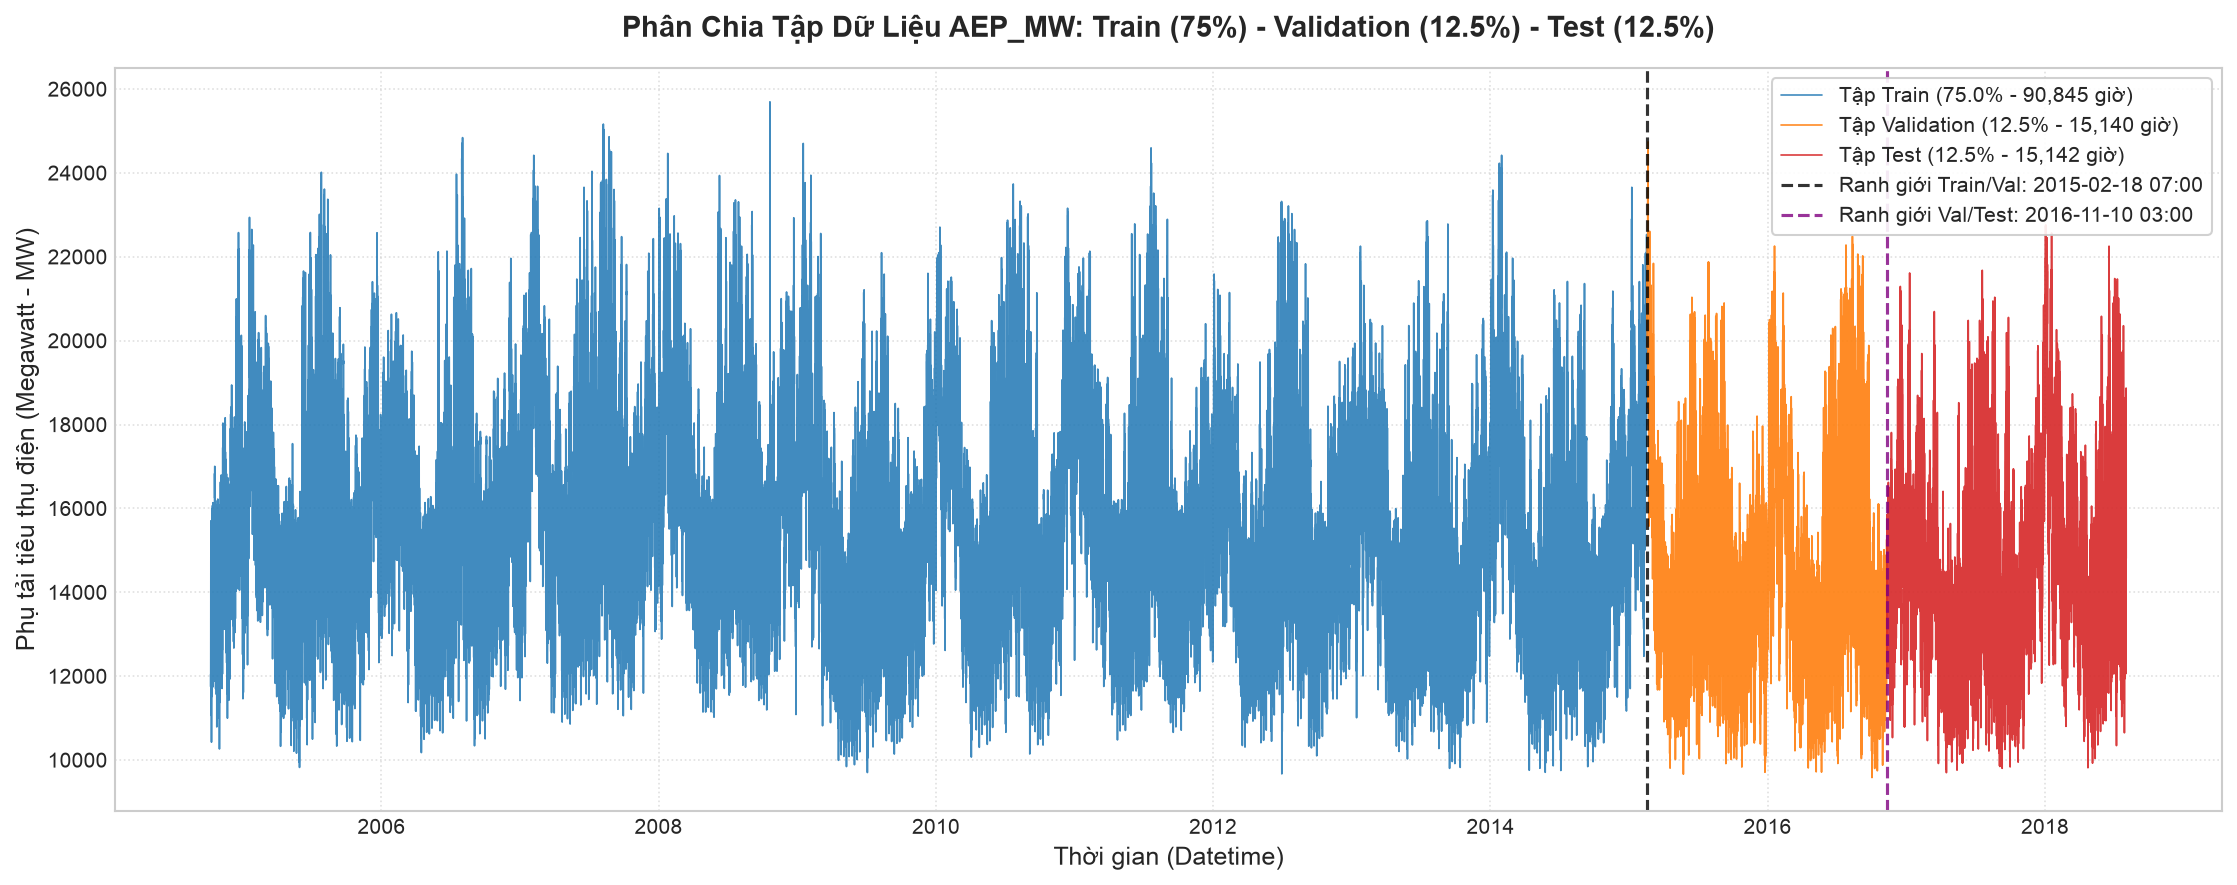

Đã lưu biểu đồ phân chia tập dữ liệu vào: ../docs/images/03_train_val_test_split.png


In [11]:
# ==============================================================================
# TRỰC QUAN HÓA PHÂN BỐ DỮ LIỆU TRAIN / VALIDATION / TEST THEO THỜI GIAN
# ==============================================================================

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)

# Vẽ chuỗi phụ tải của từng tập với màu sắc phân biệt
ax.plot(y_train.index, y_train.values, label=f'Tập Train (75.0% - {len(y_train):,} giờ)', color='#1f77b4', alpha=0.85, linewidth=0.8)
ax.plot(y_val.index, y_val.values, label=f'Tập Validation (12.5% - {len(y_val):,} giờ)', color='#ff7f0e', alpha=0.9, linewidth=0.8)
ax.plot(y_test.index, y_test.values, label=f'Tập Test (12.5% - {len(y_test):,} giờ)', color='#d62728', alpha=0.9, linewidth=0.8)

# Vẽ các đường ranh giới phân tách mốc thời gian
val_start_date = X_val.index.min()
test_start_date = X_test.index.min()

ax.axvline(x=val_start_date, color='black', linestyle='--', linewidth=1.5, alpha=0.8,
           label=f'Ranh giới Train/Val: {val_start_date.strftime("%Y-%m-%d %H:%M")}')
ax.axvline(x=test_start_date, color='purple', linestyle='--', linewidth=1.5, alpha=0.8,
           label=f'Ranh giới Val/Test: {test_start_date.strftime("%Y-%m-%d %H:%M")}')

# Định dạng đồ thị
ax.set_title('Phân Chia Tập Dữ Liệu AEP_MW: Train (75%) - Validation (12.5%) - Test (12.5%)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Thời gian (Datetime)', fontsize=12)
ax.set_ylabel('Phụ tải tiêu thụ điện (Megawatt - MW)', fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()

# Lưu biểu đồ vào thư mục docs/images/
image_path = '../docs/images/03_train_val_test_split.png'
os.makedirs(os.path.dirname(image_path), exist_ok=True)
fig.savefig(image_path, bbox_inches='tight')
print(f"Đã lưu biểu đồ phân chia tập dữ liệu vào: {image_path}")
plt.show()


**Đánh giá & Kết luận Bước 4:**
1. **Phân bổ tỷ lệ chuẩn xác:** Toàn bộ $121.127$ mẫu dữ liệu được phân chia hoàn hảo theo tỷ lệ $75\% - 12.5\% - 12.5\%$:
   - **Tập Train (75.0%):** $90.845$ giờ (từ `2004-10-08 02:00:00` đến `2015-02-18 06:00:00`, $\approx 10,4$ năm).
   - **Tập Validation (12.5%):** $15.140$ giờ (từ `2015-02-18 07:00:00` đến `2016-11-10 02:00:00`, $\approx 1,73$ năm).
   - **Tập Test (12.5%):** $15.142$ giờ (từ `2016-11-10 03:00:00` đến `2018-08-03 00:00:00`, $\approx 1,73$ năm).
2. **Bảo toàn tính liên tục & Không rò rỉ:**
   - Điểm kết thúc của Train và điểm bắt đầu của Validation cách nhau đúng $1$ giờ liên tục.
   - Điểm kết thúc của Validation và điểm bắt đầu của Test cách nhau đúng $1$ giờ liên tục.
   - Tổng số mẫu của 3 tập khớp đúng $100\%$ tổng quan sát ($90.845 + 15.140 + 15.142 = 121.127$).
3. **Sẵn sàng cho Bước 5:**
   - Ta có thể huấn luyện `XGBRegressor` trên `(X_train, y_train)` và sử dụng `eval_set=[(X_train, y_train), (X_val, y_val)]` kết hợp `early_stopping_rounds` để tìm ra số lượng cây `n_estimators` tối ưu nhất.